In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
DATA_PATH = Path("../Data/Cleaned/Nepal_Online_Payment_System.csv")

df = pd.read_csv(DATA_PATH)
df["period_end"] = pd.to_datetime(df["period_end"])

In [3]:
df.shape

(645, 11)

### How much transaction activity is happening each month across all payment instruments?

In [4]:
monthly_totals = (
    df.groupby("period_end")
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .sort_index()
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million
period_end,,
2023-07-01,100916114,5156481
2023-08-01,90886739,3985007
2023-09-01,95836096,3229087
2023-10-01,96256655,4073231
2023-11-01,82548409,3206725
2023-12-01,89227481,3733385
2024-01-01,93750989,3883287
2024-02-01,99192199,4051320
2024-03-01,96053423,4684595


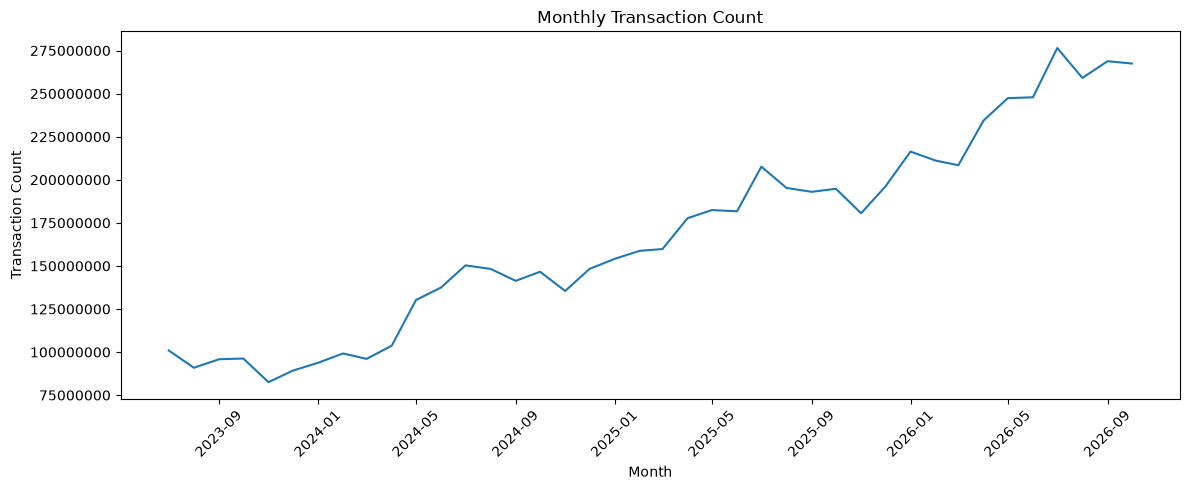

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["total_txn_count"]
)

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Transaction Count")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

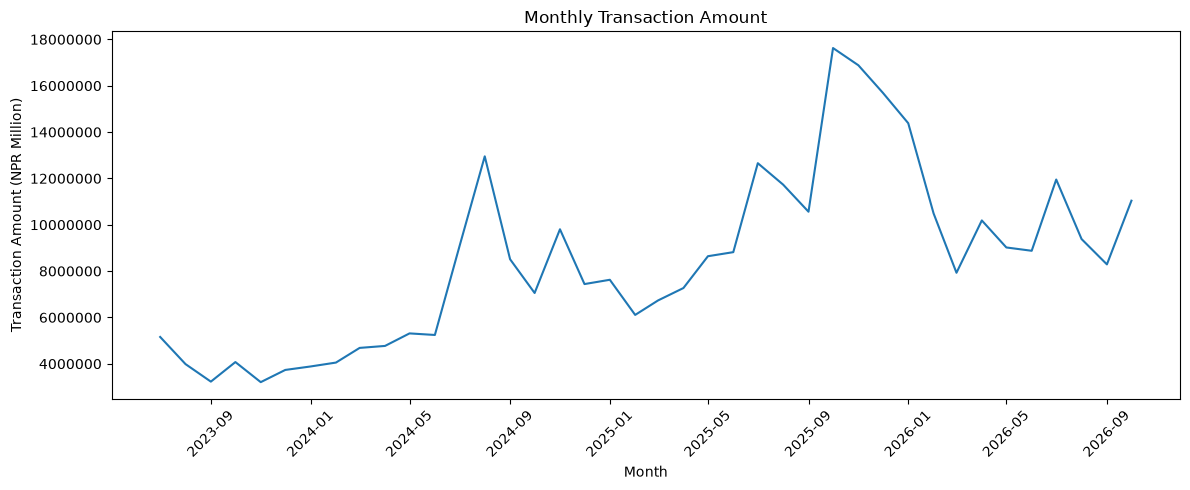

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["total_txn_amount_npr_million"]
)

plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Transaction Amount (NPR Million)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [7]:
monthly_totals["avg_transaction_value_npr"] = (
    monthly_totals["total_txn_amount_npr_million"] * 1_000_000
    / monthly_totals["total_txn_count"]
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr
period_end,,,
2023-07-01,100916114,5156481,51096.71
2023-08-01,90886739,3985007,43845.86
2023-09-01,95836096,3229087,33693.85
2023-10-01,96256655,4073231,42316.36
2023-11-01,82548409,3206725,38846.60
2023-12-01,89227481,3733385,41841.20
2024-01-01,93750989,3883287,41421.29
2024-02-01,99192199,4051320,40843.13
2024-03-01,96053423,4684595,48770.72


### Observations:
1. Monthly transaction count increased substantially over the reporting period.
2. Monthly transaction amount also increased, although not consistently.
3. Average transaction value fluctuated, rather than increasing continuously.

### How much did transaction activity increase or decrease compared with the previous month?

In [8]:
monthly_totals["count_mom_growth_pct"] = (
    monthly_totals["total_txn_count"].pct_change() * 100
)

monthly_totals["amount_mom_growth_pct"] = (
    monthly_totals["total_txn_amount_npr_million"].pct_change() * 100
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr,count_mom_growth_pct,amount_mom_growth_pct
period_end,,,,,
2023-07-01,100916114,5156481,51096.71,NaN,NaN
2023-08-01,90886739,3985007,43845.86,-9.94,-22.72
2023-09-01,95836096,3229087,33693.85,5.45,-18.97
2023-10-01,96256655,4073231,42316.36,0.44,26.14
2023-11-01,82548409,3206725,38846.60,-14.24,-21.27
2023-12-01,89227481,3733385,41841.20,8.09,16.42
2024-01-01,93750989,3883287,41421.29,5.07,4.02
2024-02-01,99192199,4051320,40843.13,5.80,4.33
2024-03-01,96053423,4684595,48770.72,-3.16,15.63


### Key observations
Transaction count growth
- Highest growth: +25.61% in May 2024.
- Largest decline: -14.24% in November 2023.
- Transaction count generally shows an upward trend over the longer period.

Transaction amount growth
- Highest growth: +72.78% in July 2024.
- Largest decline: -34.29% in September 2024.
- Transaction amount fluctuates much more than transaction count.

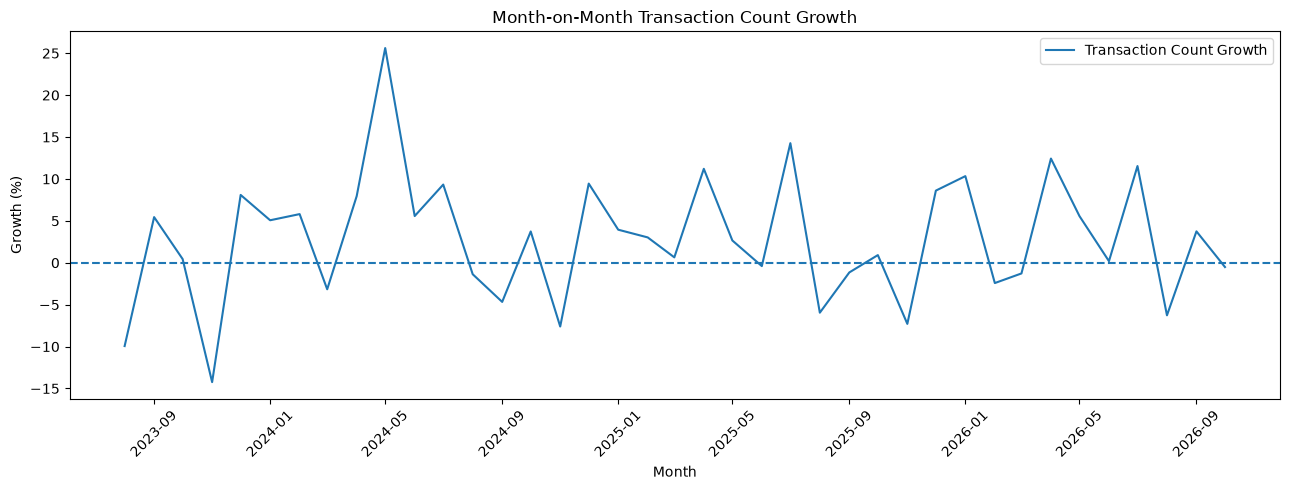

In [9]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["count_mom_growth_pct"],
    label="Transaction Count Growth"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-on-Month Transaction Count Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

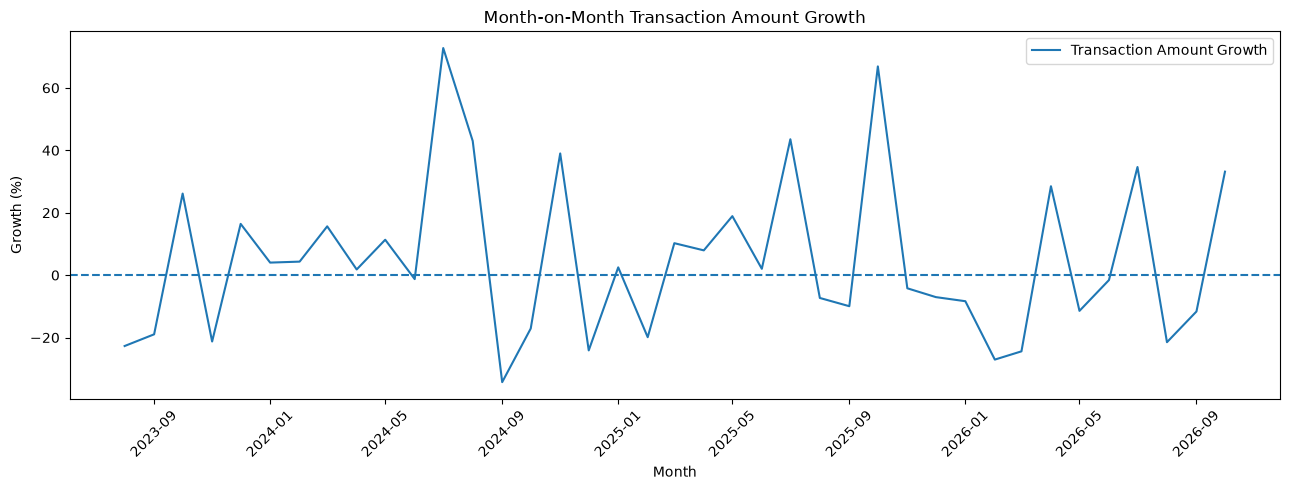

In [10]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["amount_mom_growth_pct"],
    label="Transaction Amount Growth"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-on-Month Transaction Amount Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
df[["bs_year", "bs_month"]].drop_duplicates().sort_values(
    ["bs_year", "bs_month"]
).head(20)

,bs_year,bs_month
0,2080,Asar
44,2080,Asoj
30,2080,Bhadau
128,2080,Chaitra
114,2080,Falgun
58,2080,Kartik
100,2080,Magh
72,2080,Mangsir
86,2080,Pus
16,2080,Saun


In [12]:
nepali_month_order = [
    "Baisakh", "Jestha", "Asar", "Saun",
    "Bhadau", "Asoj", "Kartik", "Mangsir",
    "Pus", "Magh", "Falgun", "Chaitra"
]

df["bs_month"] = pd.Categorical(
    df["bs_month"],
    categories=nepali_month_order,
    ordered=True
)

bs_calendar = (
    df[["bs_year", "bs_month"]]
    .drop_duplicates()
    .sort_values(["bs_year", "bs_month"])
    .reset_index(drop=True)
)

bs_calendar

,bs_year,bs_month
0,2080,Asar
1,2080,Saun
2,2080,Bhadau
3,2080,Asoj
4,2080,Kartik
5,2080,Mangsir
6,2080,Pus
7,2080,Magh
8,2080,Falgun
9,2080,Chaitra


In [13]:
bs_monthly_totals = (
    df.groupby(["bs_year", "bs_month"], observed=True)
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .reset_index()
    .sort_values(["bs_year", "bs_month"])
)

bs_monthly_totals.head(15)

,bs_year,bs_month,total_txn_count,total_txn_amount_npr_million
0,2080,Asar,100916114,5156481
1,2080,Saun,90886739,3985007
2,2080,Bhadau,95836096,3229087
3,2080,Asoj,96256655,4073231
4,2080,Kartik,82548409,3206725
5,2080,Mangsir,89227481,3733385
6,2080,Pus,93750989,3883287
7,2080,Magh,99192199,4051320
8,2080,Falgun,96053423,4684595
9,2080,Chaitra,103685697,4769436


In [14]:
bs_monthly_totals["avg_transaction_value_npr"] = (
    bs_monthly_totals["total_txn_amount_npr_million"] * 1_000_000
    / bs_monthly_totals["total_txn_count"]
)

bs_monthly_totals.head(15)

,bs_year,bs_month,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr
0,2080,Asar,100916114,5156481,51096.705923
1,2080,Saun,90886739,3985007,43845.857425
2,2080,Bhadau,95836096,3229087,33693.849549
3,2080,Asoj,96256655,4073231,42316.357243
4,2080,Kartik,82548409,3206725,38846.599696
5,2080,Mangsir,89227481,3733385,41841.201367
6,2080,Pus,93750989,3883287,41421.291033
7,2080,Magh,99192199,4051320,40843.131222
8,2080,Falgun,96053423,4684595,48770.724183
9,2080,Chaitra,103685697,4769436,45998.977082


### YoY growth for transaction count:

In [15]:
bs_monthly_totals["txn_count_yoy_growth_pct"] = (
    bs_monthly_totals
    .groupby("bs_month")["total_txn_count"]
    .pct_change() * 100
)

### YoY growth for transaction amount:

In [16]:
bs_monthly_totals["txn_amount_yoy_growth_pct"] = (
    bs_monthly_totals
    .groupby("bs_month")["total_txn_amount_npr_million"]
    .pct_change() * 100
)

In [17]:
bs_monthly_totals[
    [
        "bs_year",
        "bs_month",
        "txn_count_yoy_growth_pct",
        "txn_amount_yoy_growth_pct"
    ]
]

,bs_year,bs_month,txn_count_yoy_growth_pct,txn_amount_yoy_growth_pct
0,2080,Asar,NaN,NaN
1,2080,Saun,NaN,NaN
2,2080,Bhadau,NaN,NaN
3,2080,Asoj,NaN,NaN
4,2080,Kartik,NaN,NaN
5,2080,Mangsir,NaN,NaN
6,2080,Pus,NaN,NaN
7,2080,Magh,NaN,NaN
8,2080,Falgun,NaN,NaN
9,2080,Chaitra,NaN,NaN


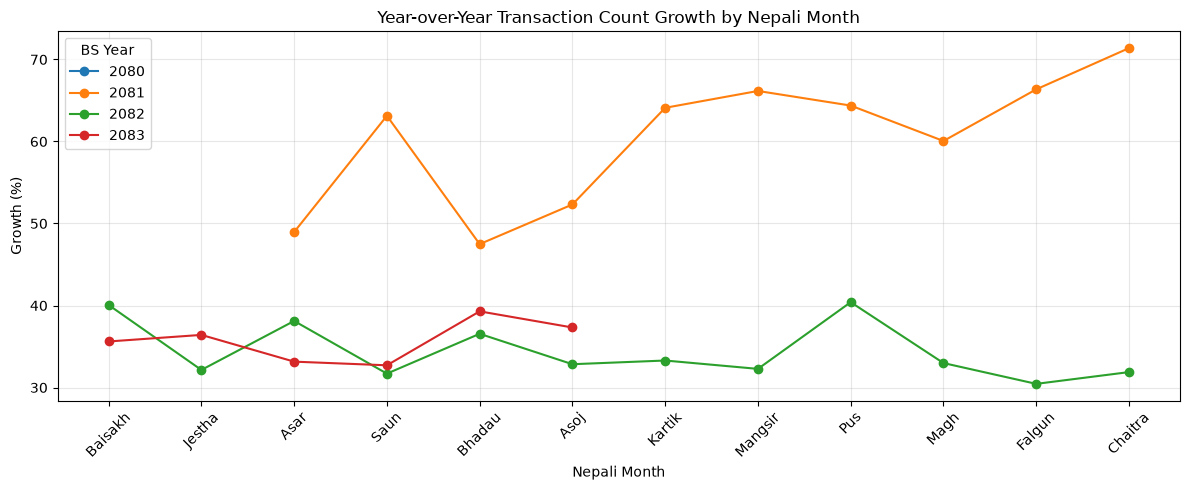

In [18]:
nepali_month_order = [
    "Baisakh", "Jestha", "Asar", "Saun",
    "Bhadau", "Asoj", "Kartik", "Mangsir",
    "Pus", "Magh", "Falgun", "Chaitra"
]

plt.figure(figsize=(12, 5))

for year, group in bs_monthly_totals.groupby("bs_year"):
    group = group.set_index("bs_month").reindex(nepali_month_order)

    plt.plot(
        nepali_month_order,
        group["txn_count_yoy_growth_pct"],
        marker="o",
        label=str(year)
    )

plt.title("Year-over-Year Transaction Count Growth by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Growth (%)")
plt.legend(title="BS Year")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

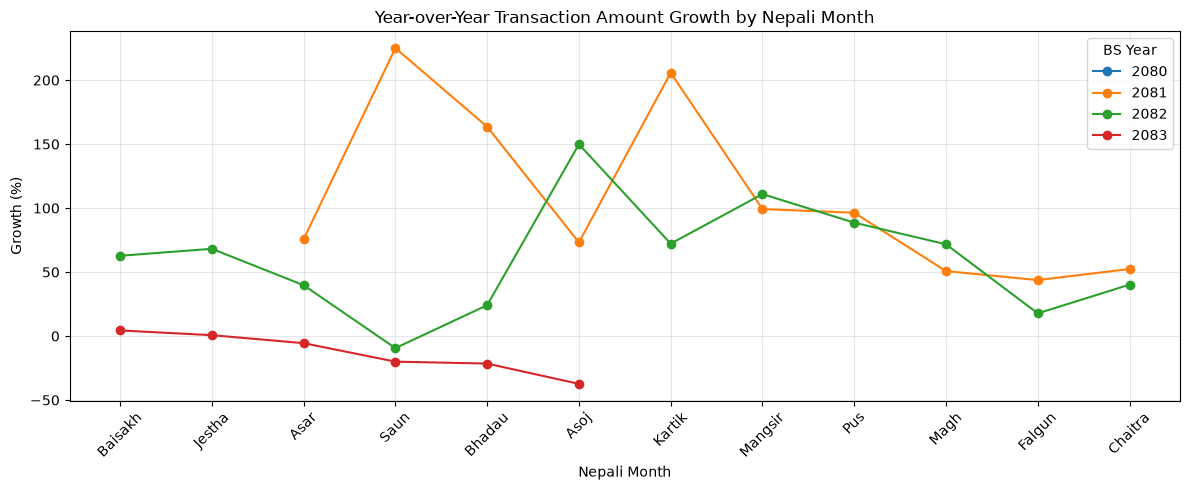

In [19]:
# Transaction Amount YoY Growth
plt.figure(figsize=(12, 5))

for year, group in bs_monthly_totals.groupby("bs_year"):
    group = group.set_index("bs_month").reindex(nepali_month_order)

    plt.plot(
        nepali_month_order,
        group["txn_amount_yoy_growth_pct"],
        marker="o",
        label=str(year)
    )

plt.title("Year-over-Year Transaction Amount Growth by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Growth (%)")
plt.legend(title="BS Year")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### overall highest and lowest monthly transaction count and transaction amount

In [20]:
# Highest and lowest transaction count
highest_txn_count = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_count"].idxmax()
]

lowest_txn_count = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_count"].idxmin()
]

# Highest and lowest transaction amount
highest_txn_amount = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_amount_npr_million"].idxmax()
]

lowest_txn_amount = bs_monthly_totals.loc[
    bs_monthly_totals["total_txn_amount_npr_million"].idxmin()
]

print("Highest Transaction Count:")
print(highest_txn_count[["bs_year", "bs_month", "total_txn_count"]])

print("\nLowest Transaction Count:")
print(lowest_txn_count[["bs_year", "bs_month", "total_txn_count"]])

print("\nHighest Transaction Amount:")
print(highest_txn_amount[["bs_year", "bs_month", "total_txn_amount_npr_million"]])

print("\nLowest Transaction Amount:")
print(lowest_txn_amount[["bs_year", "bs_month", "total_txn_amount_npr_million"]])

Highest Transaction Count:
bs_year                 2083
bs_month                Asar
total_txn_count    276461473
Name: 36, dtype: object

Lowest Transaction Count:
bs_year                2080
bs_month             Kartik
total_txn_count    82548409
Name: 4, dtype: object

Highest Transaction Amount:
bs_year                             2082
bs_month                            Asoj
total_txn_amount_npr_million    17625574
Name: 27, dtype: object

Lowest Transaction Amount:
bs_year                            2080
bs_month                         Kartik
total_txn_amount_npr_million    3206725
Name: 4, dtype: object


### Identify the highest and lowest growth months

In [21]:
# Highest and lowest transaction count growth
highest_count_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_count_yoy_growth_pct"].idxmax()
]

lowest_count_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_count_yoy_growth_pct"].idxmin()
]

# Highest and lowest transaction amount growth
highest_amount_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_amount_yoy_growth_pct"].idxmax()
]

lowest_amount_growth = bs_monthly_totals.loc[
    bs_monthly_totals["txn_amount_yoy_growth_pct"].idxmin()
]

print("Highest Transaction Count Growth:")
print(highest_count_growth[["bs_year", "bs_month", "txn_count_yoy_growth_pct"]])

print("\nLowest Transaction Count Growth:")
print(lowest_count_growth[["bs_year", "bs_month", "txn_count_yoy_growth_pct"]])

print("\nHighest Transaction Amount Growth:")
print(highest_amount_growth[["bs_year", "bs_month", "txn_amount_yoy_growth_pct"]])

print("\nLowest Transaction Amount Growth:")
print(lowest_amount_growth[["bs_year", "bs_month", "txn_amount_yoy_growth_pct"]])

Highest Transaction Count Growth:
bs_year                          2081
bs_month                      Chaitra
txn_count_yoy_growth_pct    71.383927
Name: 21, dtype: object

Lowest Transaction Count Growth:
bs_year                          2082
bs_month                       Falgun
txn_count_yoy_growth_pct    30.446204
Name: 32, dtype: object

Highest Transaction Amount Growth:
bs_year                            2081
bs_month                           Saun
txn_amount_yoy_growth_pct    225.017171
Name: 13, dtype: object

Lowest Transaction Amount Growth:
bs_year                           2083
bs_month                          Asoj
txn_amount_yoy_growth_pct   -37.377285
Name: 39, dtype: object


### Aggregate by BS year

In [22]:
bs_year_summary = (
    bs_monthly_totals
    .groupby("bs_year")
    .agg(
        total_txn_count=("total_txn_count", "sum"),
        total_txn_amount_npr_million=("total_txn_amount_npr_million", "sum"),
        avg_monthly_txn_count=("total_txn_count", "mean"),
        avg_monthly_txn_amount_npr_million=("total_txn_amount_npr_million", "mean"),
        months_reported=("bs_month", "count")
    )
    .reset_index()
)

bs_year_summary

,bs_year,total_txn_count,total_txn_amount_npr_million,avg_monthly_txn_count,avg_monthly_txn_amount_npr_million,months_reported
0,2080,948353802,40772554,9.483538e+07,4.077255e+06,10
1,2081,1788393065,93103606,1.490328e+08,7.758634e+06,12
2,2082,2401763369,145586744,2.001469e+08,1.213223e+07,12
3,2083,1567142360,58554518,2.611904e+08,9.759086e+06,6


### BS Year-over-Year Growth

In [23]:
bs_year_summary["txn_count_yoy_growth_pct"] = (
    bs_year_summary["total_txn_count"].pct_change() * 100
)

bs_year_summary["txn_amount_yoy_growth_pct"] = (
    bs_year_summary["total_txn_amount_npr_million"].pct_change() * 100
)

bs_year_summary

,bs_year,total_txn_count,total_txn_amount_npr_million,avg_monthly_txn_count,avg_monthly_txn_amount_npr_million,months_reported,txn_count_yoy_growth_pct,txn_amount_yoy_growth_pct
0,2080,948353802,40772554,9.483538e+07,4.077255e+06,10,NaN,NaN
1,2081,1788393065,93103606,1.490328e+08,7.758634e+06,12,88.578678,128.348722
2,2082,2401763369,145586744,2.001469e+08,1.213223e+07,12,34.297287,56.370682
3,2083,1567142360,58554518,2.611904e+08,9.759086e+06,6,-34.750343,-59.780323


### Which Nepali months generally have higher/lower transaction activity?

In [ ]:
bs_month_seasonality = (
    bs_monthly_totals
    .groupby("bs_month", observed=True)
    .agg(
        avg_txn_count=("total_txn_count", "mean"),
        avg_txn_amount_npr_million=("total_txn_amount_npr_million", "mean"),
        years_available=("bs_year", "nunique")
    )
    .reindex(nepali_month_order)
    .reset_index()
)

bs_month_seasonality

,bs_month,avg_txn_count,avg_txn_amount_npr_million,years_available
0,Baisakh,1.866887e+08,7.656927e+06,3
1,Jestha,1.890214e+08,7.644932e+06,3
2,Asar,1.838316e+08,9.705236e+06,4
3,Saun,1.733848e+08,9.512265e+06,4
4,Bhadau,1.747546e+08,7.647352e+06,4
5,Asoj,1.762755e+08,9.947570e+06,4
6,Kartik,1.328616e+08,9.964340e+06,3
7,Mangsir,1.445324e+08,8.955067e+06,3
8,Pus,1.547440e+08,8.629587e+06,3
9,Magh,1.563647e+08,6.882598e+06,3


In [27]:
bs_month_seasonality_readable = bs_month_seasonality.copy()

# Convert transaction count to millions
bs_month_seasonality_readable["avg_txn_count_million"] = (
    bs_month_seasonality_readable["avg_txn_count"] / 1_000_000
)

# Convert transaction amount from NPR million to NPR trillion
bs_month_seasonality_readable["avg_txn_amount_npr_trillion"] = (
    bs_month_seasonality_readable["avg_txn_amount_npr_million"] / 1_000_000
)

# Keep only readable columns
bs_month_seasonality_readable = bs_month_seasonality_readable[
    [
        "bs_month",
        "avg_txn_count_million",
        "avg_txn_amount_npr_trillion",
        "years_available"
    ]
]

bs_month_seasonality_readable.style.format({
    "avg_txn_count_million": "{:,.2f}",
    "avg_txn_amount_npr_trillion": "{:,.2f}",
    "years_available": "{:.0f}"
})

,bs_month,avg_txn_count_million,avg_txn_amount_npr_trillion,years_available
0,Baisakh,186.69,7.66,3
1,Jestha,189.02,7.64,3
2,Asar,183.83,9.71,4
3,Saun,173.38,9.51,4
4,Bhadau,174.75,7.65,4
5,Asoj,176.28,9.95,4
6,Kartik,132.86,9.96,3
7,Mangsir,144.53,8.96,3
8,Pus,154.74,8.63,3
9,Magh,156.36,6.88,3


### Key Observations – BS Month Seasonality
1. Jestha has the highest average transaction count (189.02 million).
2. Kartik has the lowest average transaction count (132.86 million).
3. Kartik records the highest average transaction amount (NPR 9.96 trillion).
4. Falgun has the lowest average transaction amount (NPR 6.45 trillion).
5. Transaction volume and transaction value follow different seasonal patterns.

Note: Monthly averages are based on 3–4 years of available data.

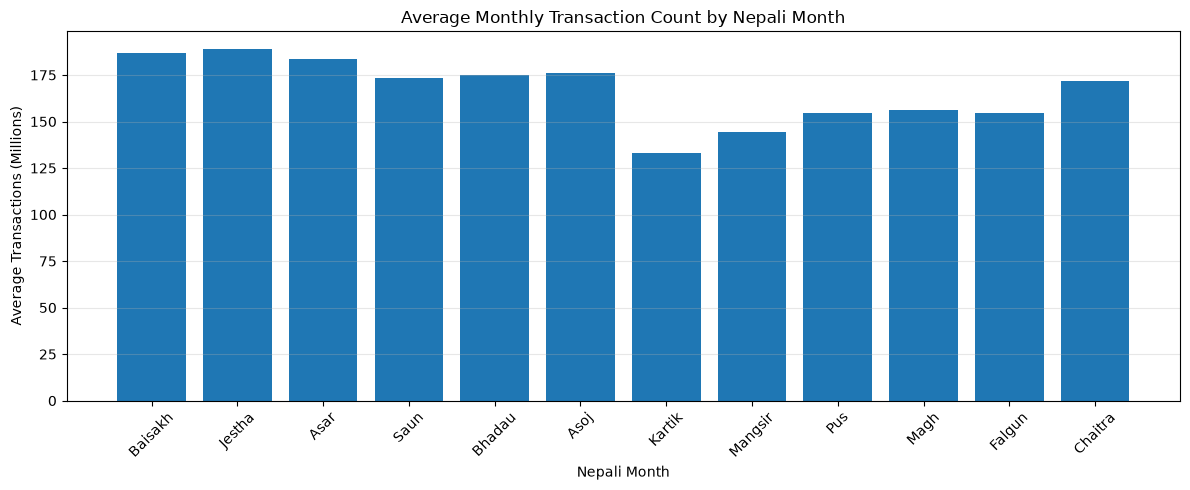

In [28]:
plt.figure(figsize=(12, 5))

plt.bar(
    bs_month_seasonality["bs_month"].astype(str),
    bs_month_seasonality["avg_txn_count"] / 1_000_000
)

plt.title("Average Monthly Transaction Count by Nepali Month")
plt.xlabel("Nepali Month")
plt.ylabel("Average Transactions (Millions)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()